Carregar os dados e importar bibliotecas


In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_text
from sklearn.metrics import accuracy_score
from sklearn import tree
import matplotlib.pyplot as plt

# Ler o ficheiro csv com os dados
data = pd.read_csv("hungarian_heart_diseases.csv")

# Queremos saber as features e o seu outcome separados por referencial (x e y)
x = data.drop(columns=["outcome"])
y = data["outcome"]

Exercício 1

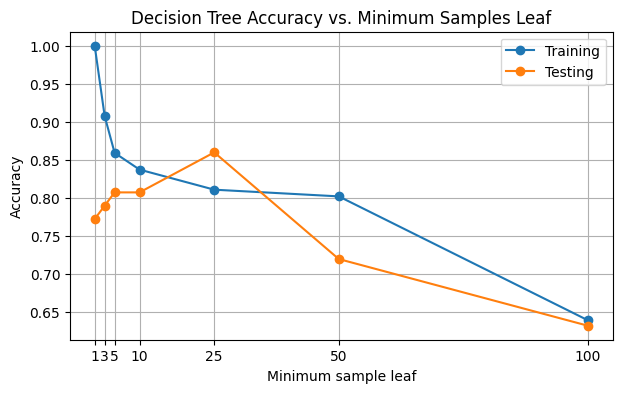

In [8]:
minimum_sample_leaf = [1,3,5,10,25,50,100]

# As acurácias que necessitamos para fazer o gráfico
training_accuracies = []
testing_accuracies = []

# Divide-se os dados em 80-20, 80% treino e 20% teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)

# Treinar e avaliar o modelo para cada valor presente em minimum_sample_leaf
for min in minimum_sample_leaf:
    classifier = DecisionTreeClassifier(min_samples_leaf=min, random_state = 1)

    # Treinar o modelo com os dados de treino
    classifier.fit(x_train, y_train)
    
    # Prever os dados de treino e de teste
    y_train_predicted = classifier.predict(x_train)
    y_test_predicted = classifier.predict(x_test)

    # Verificar quais são as acurácias para cada conjunto 
    training_accuracies.append(accuracy_score(y_train, y_train_predicted))
    testing_accuracies.append(accuracy_score(y_test, y_test_predicted))


plt.figure(figsize=(7, 4))

# Plot das acurácias do conjunto de treino
plt.plot(minimum_sample_leaf, training_accuracies, marker='o', label='Training')

# Plot das acurácias do conjunto de teste
plt.plot(minimum_sample_leaf, testing_accuracies, marker='o', label='Testing')

plt.xlabel("Minimum sample leaf")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy vs. Minimum Samples Leaf")
plt.xticks(minimum_sample_leaf)
plt.legend()
plt.grid()
plt.show()


Exercício 3


i.

Validação: 0.8771929824561403
Teste: 0.8245614035087719
|--- chest_pain <= 3.50
|   |--- oldpeak <= 1.25
|   |   |--- exercise_induce_angina <= 0.50
|   |   |   |--- thalach <= 95.00
|   |   |   |   |--- class: 1
|   |   |   |--- thalach >  95.00
|   |   |   |   |--- class: 0
|   |   |--- exercise_induce_angina >  0.50
|   |   |   |--- class: 0
|   |--- oldpeak >  1.25
|   |   |--- sex <= 0.50
|   |   |   |--- class: 0
|   |   |--- sex >  0.50
|   |   |   |--- class: 1
|--- chest_pain >  3.50
|   |--- oldpeak <= 0.90
|   |   |--- sex <= 0.50
|   |   |   |--- class: 0
|   |   |--- sex >  0.50
|   |   |   |--- trestbps <= 129.00
|   |   |   |   |--- class: 1
|   |   |   |--- trestbps >  129.00
|   |   |   |   |--- class: 0
|   |--- oldpeak >  0.90
|   |   |--- thalach <= 166.50
|   |   |   |--- oldpeak <= 1.25
|   |   |   |   |--- class: 1
|   |   |   |--- oldpeak >  1.25
|   |   |   |   |--- class: 1
|   |   |--- thalach >  166.50
|   |   |   |--- class: 0



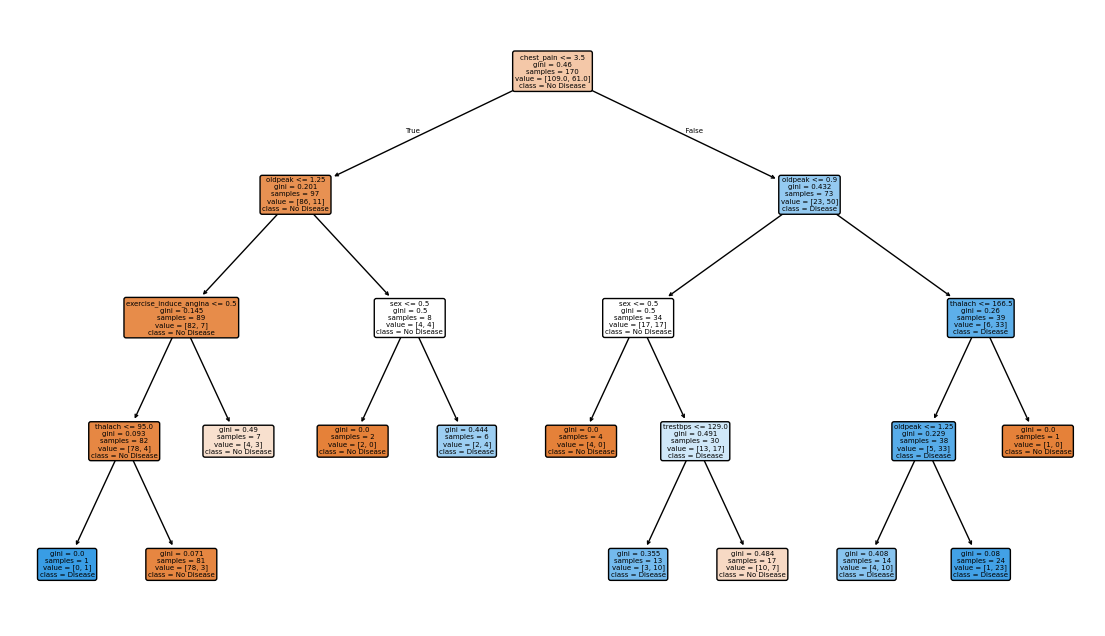

In [ ]:
# Divisão dos dados em 60% treino, 20% validação e 20% teste 
x_temp, x_test, y_temp, y_test = train_test_split(
    x, y, test_size=0.20, stratify=y, random_state=1
)

# 0.25 de 0.8 = 0.20 total
x_train, x_val, y_train, y_val = train_test_split(
    x_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=1
)  

# Inicialização das variáveis para guardar o melhor modelo e a melhor acurácia de validação
best_model = None
best_val_acc = 0
results = []

# Procura os melhores parametros para o par(max_depth, min_samples_split) para a melhor acurácia de validação.
# As profundidades da árvore testadas são 2, 3 e 4
for depth in [2, 3, 4]:
    for min_split in range(2, 101):
        clf = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_split=min_split,
            random_state=1
        )
        clf.fit(x_train, y_train)

        val_acc = accuracy_score(y_val, clf.predict(x_val))
        results.append((depth, min_split, val_acc))

        # Atualiza os valores se for o melhor modelo encontrado
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model = clf

# Diz-nos qual a melhor acurácia encontrada na validação
best_val_acc

# Avaliar o modelo final no conjunto de teste
test_acc = accuracy_score(y_test, best_model.predict(x_test))

# Desempenho
print("Validação:", best_val_acc)
print("Teste:", test_acc)  

# Regras da árvore de decisão
rules = export_text(best_model, feature_names=list(x.columns))
print(rules)

# Plot da árvore de decisão
plt.figure(figsize=(14, 8))
tree.plot_tree(
    best_model,
    feature_names=x.columns,
    class_names=['No Disease','Disease'],
    filled=True,
    rounded=True
)

plt.show()
